# Fitness app users — 04 Modelling

Eric Gomez · November 2026

Three models, each answering a question the recommendation feature depends on:

| Model | Question | Target | Inputs | Judged by |
|---|---|---|---|---|
| **M1** Calorie regression | How many calories will a user burn, given how they use the app? (for personalised goals) | calories | sessions, distance, age, gender, location | RMSE, MAE, R², interval coverage |
| **M2** Tier classification | Which engagement tier is a new user in, from imported activity alone? (for a starting plan and re-engagement nudges) | activity level | distance, calories (age, gender and location tested and dropped) | accuracy, balanced accuracy, precision, recall, F1, ROC-AUC |
| **M3** Segmentation | Do natural user types exist to design recommendations around? | none | sessions, km per session, kcal per session | Hopkins, silhouette, Davies–Bouldin, stability |

Every model is compared with a baseline that was computed first. Every score comes from data the model has
not seen. **Every choice (model, inputs, alert thresholds) is made on five-fold cross-validation inside the
training set, by a rule stated before the scores are seen.** Only then is the held-out test set of 1,000 users
scored, and it decides nothing. Every test score carries a bootstrap interval. Two structural benchmarks, derived from the data's structure (`02`),
show how close each model is to the best any model could do. They are assumption-based structural benchmarks: they hold only if the per-session rates are uniform and independent, as the tests in `02` suggest, and are not measured facts about the data.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.visualization.theme import PALETTE, save_fig, set_plot_style
set_plot_style()
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

In [2]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning)          # sklearn zero-division notes for the dummy model
from sklearn.exceptions import UndefinedMetricWarning
warnings.filterwarnings('ignore', category=UndefinedMetricWarning)

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score
from sklearn.base import clone
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

from src.data.fitness import RAW_FILE, TIER_COLORS, TIERS, clean_users, load_users
from src.data.loading import load_raw, save_interim
from src.models.evaluation import (bootstrap_ci, calibration_summary, classification_metrics, cost_threshold,
                                   cv_table, interval_coverage, mcnemar, normalised_confusion, one_se_choice,
                                   per_class_report, regression_metrics, threshold_report)
from src.visualization.presentation import save_table

SEED = 803
users = load_users()
data = users.dropna(subset=['distance_km']).reset_index(drop=True)      # 4,997 complete records
train, test = train_test_split(data, test_size=0.2, stratify=data['activity_level'], random_state=SEED)
print(f'complete records: {len(data):,}  ->  train {len(train):,} / test {len(test):,}')
print('tier shares, train:', train['activity_level'].value_counts(normalize=True).round(3).to_dict())
print('tier shares, test :', test['activity_level'].value_counts(normalize=True).round(3).to_dict())

complete records: 4,997  ->  train 3,997 / test 1,000
tier shares, train: {'Moderate': 0.347, 'Sedentary': 0.327, 'Active': 0.326}
tier shares, test : {'Moderate': 0.347, 'Sedentary': 0.327, 'Active': 0.326}


### Interpretation

- **4,997 complete records** (the three users without a distance are left out), split 80/20 into 3,997 for
  training and 1,000 for testing.
- **The split is stratified by tier**, so all three tiers keep their shares (32.6–34.7%) in both parts.
- **One split for M1 and M2.** The test set is held back until every choice for that model has been made on
  the training folds. It reports; it does not select.

## DECISION 8 — is modelling justified?

- **M1 and M2: yes.** The feature needs predictions for new users, made thousands of times. Description cannot
  provide those, and `02` showed strong enough relationships (ρ = 0.81–0.87) to be worth modelling.
- **M3: yes, as a test.** Designers often want user types (personas). Whether the data contain any is a
  question to settle before anyone designs around them.
- **Predicting Activity Level from sessions: no.** It is a fixed rule (`01`). The next cell shows what happens
  when it is treated as a model.

## DECISION 9 — targets, predictors and leakage

| Model | Target | Predictors | Left out, and why |
|---|---|---|---|
| M1 | calories | sessions, distance, age, gender, location | *Activity Level*: a band of sessions, so it adds nothing sessions do not already say |
| M2 | activity level | distance, calories; a variant adds age, gender and location | *App Sessions*: the tier is computed from it, so including it is target leakage. The demographic variant tests whether those fields add anything |
| M3 | none | sessions, km per session, kcal per session (standardised) | Raw distance and calories: both mostly restate sessions (`02`), so they would weight frequency three times |

*User ID* is used by no model. **The M2 scenario.** A new user connects a wearable or imports a year of activity
history (distance and calories) before using the app, so no session history exists yet. All of M2's
predictors are available at that moment.

## Leakage check: Activity Level from sessions

In [3]:
from sklearn.tree import DecisionTreeClassifier, export_text

skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
tree = DecisionTreeClassifier(max_depth=2, random_state=SEED)
cv_acc = cross_val_score(tree, train[['app_sessions']], train['activity_level'], cv=skf)
tree.fit(train[['app_sessions']], train['activity_level'])
print(export_text(tree, feature_names=['app_sessions']))
print('cross-validated accuracy by fold:', cv_acc.round(4).tolist())
print('held-out test accuracy:', accuracy_score(test['activity_level'], tree.predict(test[['app_sessions']])))

|--- app_sessions <= 99.50
|   |--- class: Sedentary
|--- app_sessions >  99.50
|   |--- app_sessions <= 149.50
|   |   |--- class: Moderate
|   |--- app_sessions >  149.50
|   |   |--- class: Active

cross-validated accuracy by fold: [1.0, 1.0, 1.0, 1.0, 1.0]
held-out test accuracy: 1.0


### Interpretation

- **A two-split tree recovers the rule exactly**: sessions ≤ 99.5 is Sedentary and sessions ≤ 149.5 is
  Moderate. Every fold and the test set score 100%.
- **That score is target leakage, not skill** (S. Kaufman et al., 2012). The target was computed from the input,
  so the model has learned the formula, not anything about users. Leakage like this is a common cause of
  inflated results in published machine learning (Kapoor & Narayanan, 2023).
- **Engineering decision.** Activity Level belongs in the app's code as two documented, unit-tested
  comparisons, not as a model. Google's first rule of machine learning is to launch without it when a simple
  rule does the job (Zinkevich, 2017).

## M1 Calorie regression

First an explanatory fit on the training set, to see what drives calories and whether the error is constant.

In [4]:
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan

# HC3 robust standard errors: Breusch-Pagan (below) rejects constant variance, so ordinary errors would be wrong.
ols = smf.ols('calories ~ app_sessions + distance_km + age + C(gender) + C(location)', data=train).fit(cov_type='HC3')
coef = pd.DataFrame({'coef': ols.params, 'ci_low': ols.conf_int()[0], 'ci_high': ols.conf_int()[1],
                     'p': ols.pvalues}).round(4)
display(coef)
lm, lm_p, _, _ = het_breuschpagan(ols.resid, ols.model.exog)
print(f'Breusch-Pagan LM = {lm:.1f}, p = {lm_p:.1e}  (H0: constant residual variance)')

loglog = smf.ols('np.log(calories) ~ np.log(app_sessions)', data=train).fit(cov_type='HC3')
lo, hi = loglog.conf_int().loc['np.log(app_sessions)']
print(f"log-log slope = {loglog.params['np.log(app_sessions)']:.3f} (95% CI {lo:.3f} to {hi:.3f}): "
      'a slope of 1 means calories are proportional to sessions')
_ = save_table(coef.reset_index().rename(columns={'index': 'term'}), '04_ols_coefficients')

,coef,ci_low,ci_high,p
Intercept,-0.8384,-16.0999,14.4232,0.9143
C(gender)[T.Male],-0.1652,-7.2179,6.8874,0.9634
C(location)[T.Suburban],2.1256,-6.5703,10.8216,0.6319
C(location)[T.Rural],5.2819,-3.4342,13.9979,0.2349
app_sessions,3.5355,3.3530,3.7181,0.0000
distance_km,-0.0674,-0.2886,0.1538,0.5503
age,-0.0677,-0.3578,0.2224,0.6474


Breusch-Pagan LM = 977.1, p = 8.0e-208  (H0: constant residual variance)
log-log slope = 1.010 (95% CI 0.989 to 1.032): a slope of 1 means calories are proportional to sessions
saved outputs/tables/04_ols_coefficients.csv

                   term    coef   ci_low  ci_high      p
              Intercept -0.8384 -16.0999  14.4232 0.9143
      C(gender)[T.Male] -0.1652  -7.2179   6.8874 0.9634
C(location)[T.Suburban]  2.1256  -6.5703  10.8216 0.6319
   C(location)[T.Rural]  5.2819  -3.4342  13.9979 0.2349
           app_sessions  3.5355   3.3530   3.7181 0.0000
            distance_km -0.0674  -0.2886   0.1538 0.5503
                    age -0.0677  -0.3578   0.2224 0.6474


### Interpretation

- **Calories grow by 3.54 kcal per session** (95% CI 3.35–3.72). This is the midpoint of the 2–5
  kcal-per-session band found in `02`.
- **Nothing else matters once sessions are known.** Distance adds −0.07 kcal per km (CI −0.29 to 0.15,
  p = 0.55): per session, distance and calories are unrelated (`02`). Age, gender and location are all
  indistinguishable from zero (every p ≥ 0.23).
- **The error is not constant.** The Breusch–Pagan test rejects constant variance decisively (LM = 977,
  p < 0.001; Breusch & Pagan, 1979). The intervals above therefore use heteroscedasticity-robust (HC3) standard
  errors.
- **Calories are proportional to sessions.** The log–log slope is 1.01 (CI 0.99–1.03), so doubling sessions
  doubles expected calories, and the spread doubles with them. Prediction intervals must widen for frequent
  users (below).

Then the predictive comparison: five models and a structural reference, by five-fold cross-validation on the training set.

In [5]:
NUM_R, CAT = ['app_sessions', 'distance_km', 'age'], ['gender', 'location']

def prep(num, cat=CAT):
    return ColumnTransformer([('num', StandardScaler(), num), ('cat', OneHotEncoder(drop='first'), cat)])

reg_models = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Linear: sessions only': Pipeline([('prep', ColumnTransformer([('s', 'passthrough', ['app_sessions'])])),
                                       ('model', LinearRegression())]),
    'Linear: all predictors': Pipeline([('prep', prep(NUM_R)), ('model', LinearRegression())]),
    'Random forest': Pipeline([('prep', prep(NUM_R)), ('model', RandomForestRegressor(
        n_estimators=300, min_samples_leaf=20, random_state=SEED, n_jobs=-1))]),
    'Gradient boosting': Pipeline([('prep', prep(NUM_R)), ('model', HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, early_stopping=True, random_state=SEED))]),
}
Xr_tr, yr_tr = train[NUM_R + CAT], train['calories']
Xr_te, yr_te = test[NUM_R + CAT], test['calories']
kf = KFold(5, shuffle=True, random_state=SEED)
reg_cv = cv_table(reg_models, Xr_tr, yr_tr, cv=kf, return_train=True,
                  scoring={'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2'})

# The structural rule: 3.5 kcal per session, the midpoint of the flat 2-5 rate found in 02.
# Not fitted; scored on the same validation folds as a reference benchmark, not as a competitor.
RATE = 3.5
fold = pd.DataFrame([regression_metrics(train.iloc[va]['calories'], RATE * train.iloc[va]['app_sessions'])
                     for _, va in kf.split(Xr_tr)])
reg_cv.loc[len(reg_cv)] = {'model': 'Structural rule: 3.5 kcal x sessions',
                           **{f'{m}_{s}': (fold[m].std(ddof=1) if s == 'sd' else fold[m].mean())
                              for m in ['rmse', 'mae', 'r2'] for s in ['mean', 'sd']}}
display(reg_cv[[c for c in reg_cv if 'train' not in c]].round(3))

# Analytic ceiling: Var(calories | sessions) = sessions^2 * Var(U(2, 5)) = 0.75 * sessions^2
s, c = train['app_sessions'], train['calories']
r2_ceiling = 1 - (0.75 * (s ** 2).mean()) / c.var()
print(f'analytic R-squared ceiling from the 2-5 kcal rate: {r2_ceiling:.3f}')
_ = save_table(reg_cv.round(6), '04_regression_cv')

,model,rmse_mean,rmse_sd,mae_mean,mae_sd,r2_mean,r2_sd
0,Mean baseline,187.158,3.428,153.228,4.863,-0.001,0.001
1,Linear: sessions only,113.614,2.747,93.136,2.442,0.630,0.030
2,Linear: all predictors,113.680,2.832,93.180,2.590,0.630,0.031
3,Random forest,114.971,3.418,93.843,2.858,0.621,0.036
4,Gradient boosting,116.729,3.133,94.510,2.398,0.610,0.033
5,Structural rule: 3.5 kcal x sessions,113.616,2.763,93.120,2.432,0.630,0.030


analytic R-squared ceiling from the 2-5 kcal rate: 0.630
saved outputs/tables/04_regression_cv.csv

                               model  rmse_mean  rmse_sd  rmse_train_mean   mae_mean   mae_sd  mae_train_mean   r2_mean    r2_sd  r2_train_mean
                       Mean baseline 187.157593 3.428329       187.144679 153.228327 4.862503      153.195130 -0.001016 0.001207       0.000000
               Linear: sessions only 113.613713 2.746772       113.599876  93.135566 2.441642       93.098620  0.630253 0.030084       0.631479
              Linear: all predictors 113.679823 2.832130       113.558118  93.179729 2.590438       93.039486  0.629794 0.030774       0.631749
                       Random forest 114.971138 3.418269       105.799780  93.842790 2.857533       86.405651  0.621121 0.035904       0.680337
                   Gradient boosting 116.729493 3.133083       101.077925  94.509593 2.397838       83.145657  0.609667 0.032606       0.708123
Structural rule: 3.5 kcal x sessions

### Interpretation

- **Every model beats the mean baseline by a wide margin.** RMSE falls from 187 kcal to about 114, and R²
  rises from 0 to 0.63.
- **The simplest model is the best.** Sessions alone give R² = 0.630; adding distance and demographics gives
  0.630. The flexible models do worse: random forest 0.621, gradient boosting 0.610. With nothing extra to
  find, their flexibility fits noise.
- **0.63 is an assumption-based structural benchmark.** If calories are sessions × a rate drawn evenly between 2 and 5, the rate's
  variance (0.75 × sessions²) can never be explained. That caps R² at 0.630 in theory, and the structural
  rule "3.5 kcal × sessions", which fits nothing, matches it. Cross-validated or test estimates can sit slightly
  above or below 0.630 through sampling variation. If the real rates were not uniform, the true ceiling would differ.
- **So the remaining 37% of the variance is not a modelling failure.** It is information the app does not
  collect: how intense each session was.

In [6]:
rmse = lambda t, p: float(np.sqrt(mean_squared_error(t, p)))
fitted_reg = {name: m.fit(Xr_tr, yr_tr) for name, m in reg_models.items()}
preds = {name: m.predict(Xr_te) for name, m in fitted_reg.items()}
preds['Structural rule: 3.5 kcal x sessions'] = RATE * test['app_sessions'].to_numpy()

rows = []
for name, p in preds.items():
    r2, r2_lo, r2_hi = bootstrap_ci(yr_te.to_numpy(), p, r2_score, B=2000, seed=SEED)
    e, e_lo, e_hi = bootstrap_ci(yr_te.to_numpy(), p, rmse, B=2000, seed=SEED)
    rows.append({'model': name, 'rmse': e, 'rmse_ci': f'{e_lo:.1f}-{e_hi:.1f}',
                 'mae': regression_metrics(yr_te, p)['mae'], 'r2': r2, 'r2_ci': f'{r2_lo:.3f}-{r2_hi:.3f}'})
reg_test = pd.DataFrame(rows)
base_rmse = reg_test.loc[reg_test['model'] == 'Mean baseline', 'rmse'].iat[0]
reg_test['rmse_gain_vs_mean_pct'] = 100 * (1 - reg_test['rmse'] / base_rmse)
display(reg_test.round(3))
_ = save_table(reg_test.round(6), '04_regression_test')

,model,rmse,rmse_ci,mae,r2,r2_ci,rmse_gain_vs_mean_pct
0,Mean baseline,187.963,181.3-194.8,156.896,-0.000,-0.005--0.000,0.000
1,Linear: sessions only,113.205,109.0-117.3,91.567,0.637,0.607-0.665,39.772
2,Linear: all predictors,113.188,109.0-117.3,91.616,0.637,0.607-0.665,39.782
3,Random forest,114.843,110.4-119.2,92.977,0.627,0.594-0.657,38.901
4,Gradient boosting,116.804,112.1-121.5,94.076,0.614,0.580-0.645,37.858
5,Structural rule: 3.5 kcal x sessions,113.255,109.1-117.3,91.662,0.637,0.606-0.666,39.746


saved outputs/tables/04_regression_test.csv

                               model       rmse     rmse_ci        mae        r2         r2_ci  rmse_gain_vs_mean_pct
                       Mean baseline 187.962630 181.3-194.8 156.896443 -0.000013 -0.005--0.000               0.000000
               Linear: sessions only 113.205394 109.0-117.3  91.567479  0.637259   0.607-0.665              39.772393
              Linear: all predictors 113.188221 109.0-117.3  91.615766  0.637369   0.607-0.665              39.781530
                       Random forest 114.842761 110.4-119.2  92.977054  0.626690   0.594-0.657              38.901280
                   Gradient boosting 116.803928 112.1-121.5  94.075541  0.613831   0.580-0.645              37.857899
Structural rule: 3.5 kcal x sessions 113.255476 109.1-117.3  91.662500  0.636938   0.606-0.666              39.745749


### Interpretation

- **The test set confirms the comparison.** Linear regression on sessions alone scores R² = 0.637 (95% CI
  0.607–0.665) with an RMSE of 113 kcal (109–117) and an MAE of 92 kcal. This is consistent with the structural
  benchmark of 0.630: the finite-test estimate is slightly above it by sampling variation, and its interval contains it. That is 40% less error than the
  mean baseline.
- **The flexible models are no better.** Random forest (0.627) and gradient boosting (0.614) sit inside or
  below the linear model's interval.

## DECISION 10 (M1) — which model

**Linear regression on sessions alone.** It is as accurate as every alternative and consistent with the benchmark. It has
a single, explainable coefficient ("about 3.5 kcal per session"), it is cheap enough to run on the phone, and it
needs no demographic data, which is the privacy-friendly choice (`05`).

### Prediction intervals

coverage                       coverage_low                      coverage_high                         mean_width                    
interval  Constant width Quantile regression Constant width Quantile regression Constant width Quantile regression Constant width Quantile regression
tier                                                                                                                                                 
Sedentary          1.000               0.841          0.988               0.797          1.000               0.877        298.693             181.023
Moderate           0.787               0.787          0.741               0.741          0.827               0.827        298.693             296.576
Active             0.580               0.758          0.526               0.708          0.632               0.801        298.693             415.636
All users          0.789               0.795          0.763               0.769          0.813               0.819        298.693             297.604

quantile-regression interval at 60 sessions: 133-280 kcal; at 190 sessions: 436-888 kcal
saved outputs/tables/04_prediction_intervals.csv

     tier            interval    n  coverage  coverage_low  coverage_high  mean_width
Sedentary      Constant width  327    1.0000        0.9884         1.0000    298.6930
Sedentary Quantile regression  327    0.8410        0.7974         0.8766    181.0230
 Moderate      Constant width  347    0.7867        0.7406         0.8266    298.6930
 Moderate Quantile regression  347    0.7867        0.7406         0.8266    296.5763
   Active      Constant width  326    0.5798        0.5255         0.6321    298.6930
   Active Quantile regression  326    0.7577        0.7083         0.8010    415.6358
All users      Constant width 1000    0.7890        0.7626         0.8132    298.6930
All users Quantile regression 1000    0.7950        0.7689         0.8189    297.6038
saved outputs/figures/04_A_calorie_intervals.png


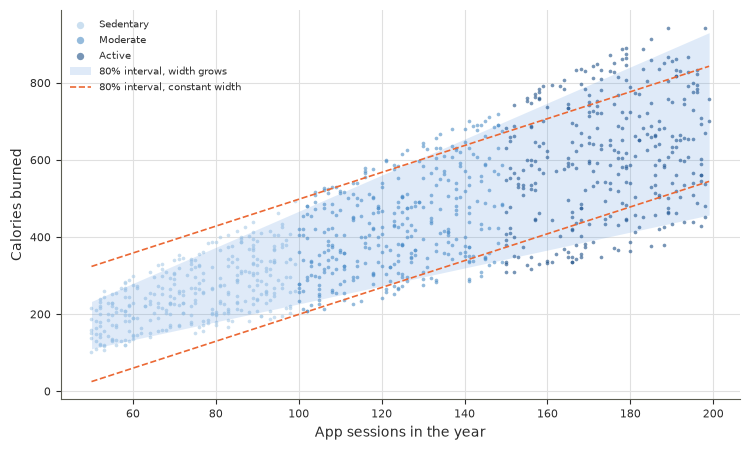

In [7]:
import statsmodels.api as sm

# 80% prediction intervals two ways: one constant width, and quantile regression that lets width grow.
q_lo = sm.QuantReg(train['calories'], sm.add_constant(train[['app_sessions']])).fit(q=0.10)
q_hi = sm.QuantReg(train['calories'], sm.add_constant(train[['app_sessions']])).fit(q=0.90)
Xq_te = sm.add_constant(test[['app_sessions']])
lo_q, hi_q = q_lo.predict(Xq_te).to_numpy(), q_hi.predict(Xq_te).to_numpy()

lin = fitted_reg['Linear: sessions only']
# Out-of-fold residuals: the band is not fitted to the same errors it is meant to cover.
res = yr_tr - cross_val_predict(reg_models['Linear: sessions only'], Xr_tr, yr_tr, cv=kf)
r_lo, r_hi = np.quantile(res, [0.10, 0.90])
centre = lin.predict(Xr_te)
lo_c, hi_c = centre + r_lo, centre + r_hi

rows = []
for tier in TIERS + ['All users']:
    m = (test['activity_level'] == tier).to_numpy() if tier != 'All users' else np.ones(len(test), bool)
    for label, lo, hi in [('Constant width', lo_c, hi_c), ('Quantile regression', lo_q, hi_q)]:
        cov = interval_coverage(yr_te.to_numpy()[m], lo[m], hi[m])
        rows.append({'tier': tier, 'interval': label, 'n': int(m.sum()), **cov})
pi = pd.DataFrame(rows)
display(pi.pivot(index='tier', columns='interval',
                 values=['coverage', 'coverage_low', 'coverage_high', 'mean_width']).round(3).loc[TIERS + ['All users']])
print('quantile-regression interval at 60 sessions: {:.0f}-{:.0f} kcal; at 190 sessions: {:.0f}-{:.0f} kcal'.format(
    *q_lo.predict([[1, 60]]), *q_hi.predict([[1, 60]]), *q_lo.predict([[1, 190]]), *q_hi.predict([[1, 190]])))
_ = save_table(pi.round(4), '04_prediction_intervals')

fig, ax = plt.subplots(figsize=(7.6, 4.6))
for t in TIERS:
    part = test[test['activity_level'] == t]
    ax.scatter(part['app_sessions'], part['calories'], s=7, alpha=0.6, color=TIER_COLORS[t], lw=0, label=t)
xs = np.linspace(50, 199, 50)
ax.fill_between(xs, q_lo.predict(sm.add_constant(xs)), q_hi.predict(sm.add_constant(xs)),
                color=PALETTE['accent'], alpha=0.15, lw=0, label='80% interval, width grows')
line = lin.named_steps['model']
ax.plot(xs, line.intercept_ + line.coef_[0] * xs + r_lo, color=PALETTE['alert'], ls='--', lw=1.2,
        label='80% interval, constant width')
ax.plot(xs, line.intercept_ + line.coef_[0] * xs + r_hi, color=PALETTE['alert'], ls='--', lw=1.2)
ax.set_xlabel('App sessions in the year')
ax.set_ylabel('Calories burned')
leg = ax.legend(loc='upper left', fontsize=7.5, markerscale=2)
fig.tight_layout()
save_fig(fig, '04_A_calorie_intervals')
plt.show()

### Interpretation

- **A single error band fails both groups.** An 80% interval of constant width (±149 kcal, set from out-of-fold
  residuals on the training users) covers 100% of Sedentary users, which is wasted width, but only 58% of Active
  users (95% CI 53–63%). It is overconfident for exactly the users who use the app most.
- **Quantile regression fixes this** (Koenker & Bassett, 1978). Its interval widens with sessions and covers
  84% (80–88%), 79% (74–83%) and 76% (71–80%) of Sedentary, Moderate and Active users, and 79.5% (77–82%) of all
  test users. The Wilson intervals (Wilson, 1927) show these coverages are close to the nominal 80%, with
  Active users slightly under it.
- **What the user would see.** At 60 sessions a year, the estimate is 133–280 kcal; at 190 sessions,
  436–888 kcal. The app should show a range that widens with activity, never a single number.

### Which inputs matter (permutation importance on the test set)

This explains the model already chosen; it selects nothing.

In [8]:
from sklearn.inspection import permutation_importance

pim = permutation_importance(fitted_reg['Gradient boosting'], Xr_te, yr_te, n_repeats=20,
                             random_state=SEED, scoring='r2')
imp = (pd.DataFrame({'feature': NUM_R + CAT, 'r2_drop_mean': pim.importances_mean, 'r2_drop_sd': pim.importances_std})
       .sort_values('r2_drop_mean', ascending=False).round(4))
display(imp)
_ = save_table(imp, '04_permutation_importance')

,feature,r2_drop_mean,r2_drop_sd
0,app_sessions,1.2125,0.0287
1,distance_km,0.0110,0.0026
4,location,-0.0020,0.0022
2,age,-0.0021,0.0040
3,gender,-0.0023,0.0008


saved outputs/tables/04_permutation_importance.csv

     feature  r2_drop_mean  r2_drop_sd
app_sessions        1.2125      0.0287
 distance_km        0.0110      0.0026
    location       -0.0020      0.0022
         age       -0.0021      0.0040
      gender       -0.0023      0.0008


### Interpretation

- **Sessions carry the model.** Shuffling them drops R² by 1.21, below zero: the model collapses.
- **Everything else is noise.** Distance moves R² by 0.011, and age, gender and location by less than 0.003,
  inside the run-to-run variation. This matches the coefficients above and the null results in `03`.

## M2 Tier classification

In [9]:
NUM_C = ['distance_km', 'calories', 'age']
ACTIVITY = ['distance_km', 'calories']
Xc_tr, yc_tr = train[NUM_C + CAT], train['activity_level'].astype(str)
Xc_te, yc_te = test[NUM_C + CAT], test['activity_level'].astype(str)

# Each pipeline selects its own columns, so every model receives the same frame.
clf_models = {
    'Majority-class baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic regression: distance and calories': Pipeline([
        ('prep', ColumnTransformer([('num', StandardScaler(), ACTIVITY)])), ('model', LogisticRegression(max_iter=2000))]),
    'Logistic regression: all inputs': Pipeline([('prep', prep(NUM_C)), ('model', LogisticRegression(max_iter=2000))]),
    'k-nearest neighbours (k = 25)': Pipeline([('prep', prep(NUM_C)), ('model', KNeighborsClassifier(25))]),
    'SVM (RBF kernel)': Pipeline([('prep', prep(NUM_C)), ('model', CalibratedClassifierCV(
        SVC(C=1.0, random_state=SEED), ensemble=False))]),
    'Random forest': Pipeline([('prep', prep(NUM_C)), ('model', RandomForestClassifier(
        n_estimators=300, min_samples_leaf=10, random_state=SEED, n_jobs=-1))]),
    'Gradient boosting': Pipeline([('prep', prep(NUM_C)), ('model', HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, early_stopping=True, random_state=SEED))]),
    'Logistic regression: demographics only': Pipeline([
        ('prep', ColumnTransformer([('num', StandardScaler(), ['age']), ('cat', OneHotEncoder(drop='first'), CAT)])),
        ('model', LogisticRegression(max_iter=2000))]),
}
CLF_SCORING = {'accuracy': 'accuracy', 'balanced_accuracy': 'balanced_accuracy',
               'precision_macro': 'precision_macro', 'recall_macro': 'recall_macro',
               'f1_macro': 'f1_macro', 'roc_auc_ovr': 'roc_auc_ovr'}
clf_cv = cv_table(clf_models, Xc_tr, yc_tr, cv=skf, scoring=CLF_SCORING, return_train=True)

# Structural Bayes rule: the tier posterior implied by the data's structure (02), with sessions unseen.
S = np.arange(50, 200)
BAND = np.select([S < 100, S < 150], [0, 1], 2)

def structural_proba(distance, calories):
    """P(tier | distance, calories) if sessions are flat on 50-199, distance flat on 0.5-1.0 x sessions
    and calories flat on 2-5 x sessions, each rounded to a whole number. Columns follow TIERS."""
    d = np.asarray(distance, float)[:, None]
    c = np.asarray(calories, float)[:, None]
    like = (((d >= 0.5 * S - 0.5) & (d <= S + 0.5)) / (0.5 * S + 1)) *            (((c >= 2 * S - 0.5) & (c <= 5 * S + 0.5)) / (3 * S + 1))
    post = np.stack([like[:, BAND == k].sum(axis=1) for k in range(3)], axis=1)
    return post / post.sum(axis=1, keepdims=True)

fold = []
for _, va in skf.split(Xc_tr, yc_tr):
    part = train.iloc[va]
    P = structural_proba(part['distance_km'], part['calories'])
    fold.append(classification_metrics(part['activity_level'].astype(str), np.array(TIERS)[P.argmax(1)],
                                       proba=P, labels=TIERS))
fold = pd.DataFrame(fold)
clf_cv.loc[len(clf_cv)] = {'model': 'Structural Bayes rule (reference benchmark)',
                           **{f'{m}_{s}': (fold[m].std(ddof=1) if s == 'sd' else fold[m].mean())
                              for m in CLF_SCORING for s in ['mean', 'sd']}}
display(clf_cv[[c for c in clf_cv if 'train' not in c]].round(3))
_ = save_table(clf_cv.round(6), '04_classification_cv')

,model,accuracy_mean,accuracy_sd,balanced_accuracy_mean,balanced_accuracy_sd,precision_macro_mean,precision_macro_sd,recall_macro_mean,recall_macro_sd,f1_macro_mean,f1_macro_sd,roc_auc_ovr_mean,roc_auc_ovr_sd
0,Majority-class baseline,0.347,0.001,0.333,0.000,0.116,0.000,0.333,0.000,0.172,0.000,0.500,0.000
1,Logistic regression: distance and calories,0.775,0.011,0.777,0.011,0.780,0.007,0.777,0.011,0.778,0.009,0.924,0.007
2,Logistic regression: all inputs,0.774,0.011,0.776,0.012,0.778,0.009,0.776,0.012,0.776,0.011,0.924,0.007
3,k-nearest neighbours (k = 25),0.767,0.014,0.769,0.014,0.773,0.012,0.769,0.014,0.770,0.013,0.919,0.006
4,SVM (RBF kernel),0.779,0.014,0.780,0.014,0.787,0.014,0.780,0.014,0.782,0.014,0.923,0.007
5,Random forest,0.773,0.015,0.774,0.015,0.782,0.014,0.774,0.015,0.777,0.015,0.928,0.007
6,Gradient boosting,0.765,0.008,0.766,0.008,0.773,0.007,0.766,0.008,0.768,0.008,0.923,0.004
7,Logistic regression: demographics only,0.349,0.014,0.343,0.012,0.358,0.124,0.343,0.012,0.293,0.017,0.508,0.013
8,Structural Bayes rule (reference benchmark),0.784,0.017,0.785,0.017,0.790,0.015,0.785,0.017,0.787,0.016,0.935,0.006


saved outputs/tables/04_classification_cv.csv

                                      model  accuracy_mean  accuracy_sd  accuracy_train_mean  balanced_accuracy_mean  balanced_accuracy_sd  balanced_accuracy_train_mean  precision_macro_mean  precision_macro_sd  precision_macro_train_mean  recall_macro_mean  recall_macro_sd  recall_macro_train_mean  f1_macro_mean  f1_macro_sd  f1_macro_train_mean  roc_auc_ovr_mean  roc_auc_ovr_sd  roc_auc_ovr_train_mean
                    Majority-class baseline       0.346760     0.000691             0.346760                0.333333              0.000000                      0.333333              0.115587            0.000230                    0.115587           0.333333         0.000000                 0.333333       0.171651     0.000254             0.171651          0.500000        0.000000                0.500000
 Logistic regression: distance and calories       0.775083     0.010551             0.777020                0.776675              0.011140 

### Interpretation

- **Six classifiers land within 1.4 points of each other**: logistic regression on distance and calories
  77.5%, logistic regression with demographics added 77.4%, SVM 77.9%, random forest 77.3%, k-nearest neighbours
  76.7% and gradient boosting 76.5%. All are more than double the 34.7% majority baseline. Macro-averaged F1 is
  0.77–0.78 and ROC-AUC 0.92–0.93.
- **Demographics add nothing.** Adding age, gender and location to distance and calories moves accuracy from
  77.5% to 77.4%. On their own they score 34.9%, no better than always guessing Moderate, with a ROC-AUC of
  0.51, which is chance.
- **The models are at the structural benchmark.** The structural Bayes rule computes each tier's probability exactly from
  the structure in `02`. Sessions must lie between the distance and twice the distance, and between a fifth and
  half of the calories, so the posterior follows without fitting anything. The most probable tier is the best
  possible guess, so its accuracy, 78.4%, estimates the lowest achievable error (the Bayes error; James et al.,
  2021), provided the inferred structure is right. The fitted models are within two points of it.

## DECISION 10 (M2) — which model, by a rule fixed in advance

The choice is made here, on the training folds, before any test score is computed:

1. **Candidates:** the six classifiers above. The baseline, the demographics-only model and the Bayes rule are
   references, not candidates.
2. **Tie rule:** the one-standard-error rule (James et al., 2021). Any model whose mean cross-validated accuracy
   is within one standard error of the best is treated as tied with it.
3. **Among tied models, the simplest wins,** in this order: fewer inputs first (data minimisation, `05`), then a
   linear model before a flexible one (explainable, cheap to run on the phone).

In [10]:
# The rule and the order are fixed before any test score exists (DECISION 10, M2).
# Simplest first: fewer inputs, then a linear model before a flexible one.
SIMPLICITY = ['Logistic regression: distance and calories', 'Logistic regression: all inputs',
              'k-nearest neighbours (k = 25)', 'SVM (RBF kernel)', 'Random forest', 'Gradient boosting']
CHOSEN, cand = one_se_choice(clf_cv, 'accuracy', SIMPLICITY, n_folds=skf.get_n_splits())
best = cand.loc[cand['accuracy_mean'].idxmax()]
print(f"best cross-validated accuracy: {best['model']} {best['accuracy_mean']:.4f}; "
      f"one standard error = {best['accuracy_sd'] / np.sqrt(skf.get_n_splits()):.4f}")
display(cand[['model', 'accuracy_mean', 'accuracy_sd', 'tied_with_best']].round(4))
print('chosen on the training folds, before the test set is scored:', CHOSEN)

best cross-validated accuracy: SVM (RBF kernel) 0.7786; one standard error = 0.0064


,model,accuracy_mean,accuracy_sd,tied_with_best
1,Logistic regression: distance and calories,0.7751,0.0106,True
2,Logistic regression: all inputs,0.7738,0.0114,True
3,k-nearest neighbours (k = 25),0.7671,0.0136,False
4,SVM (RBF kernel),0.7786,0.0144,True
5,Random forest,0.7733,0.0152,True
6,Gradient boosting,0.7646,0.0078,False


chosen on the training folds, before the test set is scored: Logistic regression: distance and calories


### Interpretation

- **The SVM has the best cross-validated accuracy** (77.9%), but one standard error is 0.6 points. Logistic
  regression on distance and calories (77.5%), logistic regression with demographics (77.4%) and the random forest
  (77.3%) are all tied with it.
- **Chosen: logistic regression on distance and calories.** It is the simplest tied model and needs no
  demographic data. Its probabilities are checked for calibration below rather than assumed.
- **What this corrects.** An earlier version of this notebook chose logistic regression because it had the
  highest *test* accuracy. That uses the test set to make a decision and makes the winning score optimistic
  (Cawley & Talbot, 2010). The choice here is the same kind of model, but it is now made without the test set.

### Overfitting check: training folds against validation folds

In [11]:
# Training-fold scores are a diagnostic of memorisation, never evidence of performance.
fits = [('M1 calories', 'R²', reg_cv, 'r2'), ('M2 tier', 'accuracy', clf_cv, 'accuracy')]
gap = pd.concat([t.dropna(subset=[f'{k}_train_mean'])
                  .loc[lambda d: ~d['model'].str.contains('baseline|demographics only')]
                  .assign(task=task, metric=metric, train=lambda d: d[f'{k}_train_mean'], validation=lambda d: d[f'{k}_mean'])
                 for task, metric, t, k in fits])[['task', 'model', 'metric', 'train', 'validation']]
gap['gap'] = gap['train'] - gap['validation']
display(gap.round(3))
iters = {'M1 gradient boosting': clone(reg_models['Gradient boosting']).fit(Xr_tr, yr_tr).named_steps['model'].n_iter_,
         'M2 gradient boosting': clone(clf_models['Gradient boosting']).fit(Xc_tr, yc_tr).named_steps['model'].n_iter_}
print('boosting rounds kept by early stopping (of 300 allowed):', iters)
_ = save_table(gap.round(4), '04_overfitting')

,task,model,metric,train,validation,gap
1,M1 calories,Linear: sessions only,R²,0.631,0.630,0.001
2,M1 calories,Linear: all predictors,R²,0.632,0.630,0.002
3,M1 calories,Random forest,R²,0.680,0.621,0.059
4,M1 calories,Gradient boosting,R²,0.708,0.610,0.098
1,M2 tier,Logistic regression: distance and calories,accuracy,0.777,0.775,0.002
2,M2 tier,Logistic regression: all inputs,accuracy,0.778,0.774,0.004
3,M2 tier,k-nearest neighbours (k = 25),accuracy,0.790,0.767,0.023
4,M2 tier,SVM (RBF kernel),accuracy,0.787,0.779,0.009
5,M2 tier,Random forest,accuracy,0.837,0.773,0.064
6,M2 tier,Gradient boosting,accuracy,0.882,0.765,0.117


boosting rounds kept by early stopping (of 300 allowed): {'M1 gradient boosting': 82, 'M2 gradient boosting': 60}
saved outputs/tables/04_overfitting.csv

       task                                      model   metric  train  validation    gap
M1 calories                      Linear: sessions only       R² 0.6315      0.6303 0.0012
M1 calories                     Linear: all predictors       R² 0.6317      0.6298 0.0020
M1 calories                              Random forest       R² 0.6803      0.6211 0.0592
M1 calories                          Gradient boosting       R² 0.7081      0.6097 0.0985
    M2 tier Logistic regression: distance and calories accuracy 0.7770      0.7751 0.0019
    M2 tier            Logistic regression: all inputs accuracy 0.7778      0.7738 0.0040
    M2 tier              k-nearest neighbours (k = 25) accuracy 0.7897      0.7671 0.0226
    M2 tier                           SVM (RBF kernel) accuracy 0.7873      0.7786 0.0087
    M2 tier                        

### Interpretation

- **The linear models do not memorise.** Training and validation scores differ by 0.2 points of accuracy and
  0.001–0.002 of R².
- **The flexible models do.** The random forest scores 83.7% on its training folds and 77.3% on the validation
  folds, a gap of 6.4 points; gradient boosting 88.2% against 76.5%, a gap of 11.8. For calories, their R² gaps
  are 0.06 and 0.10. Early stopping kept 60 (tier) and 82 (calories) of the 300 boosting rounds allowed, so
  it limited but did not prevent the memorisation.
- **So their extra flexibility is spent on noise.** That is why they score no better out of sample, and why
  they gain most when copies leak across the split (below).

### The test set, scored once the choices above are fixed

In [12]:
fitted_clf = {name: m.fit(Xc_tr, yc_tr) for name, m in clf_models.items()}
acc = lambda t, p: float(np.mean(t == p))
f1m = lambda t, p: float(f1_score(t, p, average='macro', labels=TIERS, zero_division=0))

rows, test_pred = [], {}
for name, m in fitted_clf.items():
    p = m.predict(Xc_te)
    proba = m.predict_proba(Xc_te)[:, [list(m.classes_).index(t) for t in TIERS]]
    test_pred[name] = p
    mets = classification_metrics(yc_te, p, proba=proba, labels=TIERS)
    a, a_lo, a_hi = bootstrap_ci(yc_te.to_numpy(), p, acc, B=2000, seed=SEED)
    f, f_lo, f_hi = bootstrap_ci(yc_te.to_numpy(), p, f1m, B=2000, seed=SEED)
    rows.append({'model': name, **mets, 'accuracy_ci': f'{a_lo:.3f}-{a_hi:.3f}', 'f1_macro_ci': f'{f_lo:.3f}-{f_hi:.3f}'})
P = structural_proba(test['distance_km'], test['calories'])
test_pred['Structural Bayes rule'] = np.array(TIERS)[P.argmax(1)]
rows.append({'model': 'Structural Bayes rule (reference benchmark)',
             **classification_metrics(yc_te, test_pred['Structural Bayes rule'], proba=P, labels=TIERS)})
clf_test = pd.DataFrame(rows)
display(clf_test.round(3))
_ = save_table(clf_test.round(6), '04_classification_test')

from src.analysis.hypothesis import holm_adjust
pairs = [(CHOSEN, other) for other in ['Logistic regression: all inputs', 'Gradient boosting', 'SVM (RBF kernel)',
                                       'Random forest', 'Structural Bayes rule']]
mc = pd.DataFrame([{'model_a': a, 'model_b': b, **mcnemar(yc_te, test_pred[a], test_pred[b])} for a, b in pairs])
mc['p_holm'] = holm_adjust(mc['p_value'])
display(mc.round(4))
_ = save_table(mc.round(5), '04_mcnemar')

,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr,accuracy_ci,f1_macro_ci
0,Majority-class baseline,0.347,0.333,0.116,0.333,0.172,0.500,0.317-0.376,0.160-0.182
1,Logistic regression: distance and calories,0.786,0.789,0.784,0.789,0.786,0.927,0.760-0.811,0.760-0.810
2,Logistic regression: all inputs,0.782,0.785,0.781,0.785,0.782,0.927,0.756-0.806,0.757-0.806
3,k-nearest neighbours (k = 25),0.772,0.774,0.774,0.774,0.774,0.924,0.745-0.799,0.747-0.799
4,SVM (RBF kernel),0.767,0.769,0.770,0.769,0.769,0.926,0.738-0.792,0.740-0.793
5,Random forest,0.777,0.779,0.781,0.779,0.779,0.930,0.750-0.803,0.753-0.805
6,Gradient boosting,0.746,0.748,0.747,0.748,0.747,0.924,0.717-0.773,0.720-0.774
7,Logistic regression: demographics only,0.337,0.331,0.309,0.331,0.286,0.507,0.308-0.368,0.259-0.313
8,Structural Bayes rule (reference benchmark),0.780,0.782,0.781,0.782,0.781,0.936,NaN,NaN


saved outputs/tables/04_classification_test.csv

                                      model  accuracy  balanced_accuracy  precision_macro  recall_macro  f1_macro  roc_auc_ovr accuracy_ci f1_macro_ci
                    Majority-class baseline     0.347           0.333333         0.115667      0.333333  0.171740     0.500000 0.317-0.376 0.160-0.182
 Logistic regression: distance and calories     0.786           0.788715         0.784212      0.788715  0.785780     0.927380 0.760-0.811 0.760-0.810
            Logistic regression: all inputs     0.782           0.784572         0.780852      0.784572  0.782304     0.926506 0.756-0.806 0.757-0.806
              k-nearest neighbours (k = 25)     0.772           0.773989         0.774052      0.773989  0.773643     0.924442 0.745-0.799 0.747-0.799
                           SVM (RBF kernel)     0.767           0.769009         0.769665      0.769009  0.768837     0.925756 0.738-0.792 0.740-0.793
                              Random forest  

,model_a,model_b,a_right_b_wrong,a_wrong_b_right,p_value,p_holm
0,Logistic regression: distance and calories,Logistic regression: all inputs,11,7,0.4807,1.0000
1,Logistic regression: distance and calories,Gradient boosting,91,51,0.0010,0.0050
2,Logistic regression: distance and calories,SVM (RBF kernel),39,20,0.0183,0.0733
3,Logistic regression: distance and calories,Random forest,45,36,0.3742,1.0000
4,Logistic regression: distance and calories,Structural Bayes rule,27,21,0.4709,1.0000


saved outputs/tables/04_mcnemar.csv

                                   model_a                         model_b  a_right_b_wrong  a_wrong_b_right  p_value  p_holm
Logistic regression: distance and calories Logistic regression: all inputs               11                7  0.48068 1.00000
Logistic regression: distance and calories               Gradient boosting               91               51  0.00099 0.00497
Logistic regression: distance and calories                SVM (RBF kernel)               39               20  0.01834 0.07335
Logistic regression: distance and calories                   Random forest               45               36  0.37417 1.00000
Logistic regression: distance and calories           Structural Bayes rule               27               21  0.47088 1.00000


### Interpretation

- **The chosen model scores 78.6% on the test set** (95% CI 76.0–81.1), with a balanced accuracy of 78.9%, macro
  precision 0.784, macro recall 0.789, macro F1 0.786 and ROC-AUC 0.927.
- **Dropping demographics cost nothing.** The version with age, gender and location scores 78.2%; the two
  models disagree on only 18 of the 1,000 users (11 against 7, p = 0.48).
- **It sits at the structural benchmark.** The structural Bayes rule, a reference point estimate with no interval, scores
  78.0% on the same users. The McNemar test, which compares two classifiers on the same test records
  (Dietterich, 1998), finds no difference (27 against 21 discordant records, p = 0.47). A fitted model can land
  slightly above the Bayes rule on one test set by chance; in cross-validation the rule is ahead (78.4% against
  77.5%).
- **Against the other models**, after the Holm correction across five comparisons, it beats gradient boosting
  (91 against 51, p = 0.005) and ties the SVM (p = 0.07) and the random forest (p = 1).

### Per-tier performance and the alert threshold

,class,precision,recall,f1,support
0,Sedentary,0.840,0.899,0.869,327
1,Moderate,0.707,0.654,0.680,347
2,Active,0.805,0.813,0.809,326


predicted,Sedentary,Moderate,Active
true,,,
Sedentary,0.899,0.101,0.000
Moderate,0.161,0.654,0.184
Active,0.000,0.187,0.813


predicted,Sedentary,Moderate,Active
true,,,
Sedentary,294,33,0
Moderate,56,227,64
Active,0,61,265


saved outputs/tables/04_confusion_counts.csv

     true  Sedentary  Moderate  Active
Sedentary        294        33       0
 Moderate         56       227      64
   Active          0        61     265
thresholds chosen on the training folds; precision, recall and counts are on the test set


,miss_cost_ratio,threshold,flagged,precision,recall,false_alarms,missed
0,default 0.5,0.50,347,0.844,0.896,54,34
1,1:1,0.41,372,0.812,0.924,70,25
2,3:1,0.25,425,0.736,0.957,112,14
3,5:1,0.11,490,0.661,0.991,166,3


saved outputs/tables/04_sedentary_thresholds.csv

miss_cost_ratio  threshold  flagged  precision  recall  false_alarms  missed
    default 0.5       0.50      347     0.8444  0.8960            54      34
            1:1       0.41      372     0.8118  0.9235            70      25
            3:1       0.25      425     0.7365  0.9572           112      14
            5:1       0.11      490     0.6612  0.9908           166       3
saved outputs/figures/04_B_tier_classifier.png


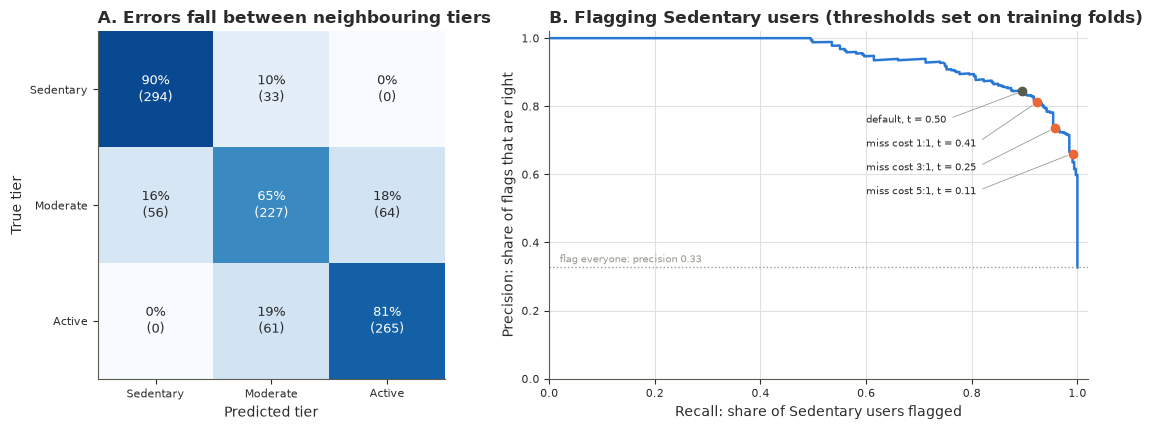

In [13]:
from sklearn.metrics import confusion_matrix, precision_recall_curve

chosen = fitted_clf[CHOSEN]
pred_c = test_pred[CHOSEN]
display(per_class_report(yc_te, pred_c, TIERS).round(3))
cm = normalised_confusion(yc_te, pred_c, TIERS)
counts = pd.DataFrame(confusion_matrix(yc_te, pred_c, labels=TIERS), index=cm.index, columns=cm.columns)
display(cm.round(3)); display(counts)
_ = save_table(counts.reset_index(), '04_confusion_counts')

# Thresholds are chosen on out-of-fold predictions for the training users; the test set only reports them.
oof = cross_val_predict(clf_models[CHOSEN], Xc_tr, yc_tr, cv=skf, method='predict_proba')
classes = list(chosen.classes_)
p_sed_oof, y_sed_oof = oof[:, classes.index('Sedentary')], (yc_tr == 'Sedentary').to_numpy()
proba_c = chosen.predict_proba(Xc_te)
p_sed = proba_c[:, classes.index('Sedentary')]
y_sed = (yc_te == 'Sedentary').to_numpy()

grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
rows = [{'miss_cost_ratio': 'default 0.5', **threshold_report(y_sed, p_sed, 0.5)}]
for ratio in [1, 3, 5]:          # cost of missing a low-engagement user : cost of one unneeded nudge
    t = cost_threshold(y_sed_oof, p_sed_oof, ratio, grid)
    rows.append({'miss_cost_ratio': f'{ratio}:1', **threshold_report(y_sed, p_sed, t)})
op = pd.DataFrame(rows)
print('thresholds chosen on the training folds; precision, recall and counts are on the test set')
display(op.round(3))
_ = save_table(op.round(4), '04_sedentary_thresholds')

prec, rec, thr = precision_recall_curve(y_sed, p_sed)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={'width_ratios': [1, 1.15]})
ax = axes[0]
im = ax.imshow(cm.to_numpy(), cmap='Blues', vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        v = cm.iat[i, j]
        ax.text(j, i, f'{v:.0%}\n({counts.iat[i, j]})', ha='center', va='center', fontsize=9.5, color='white' if v > 0.55 else PALETTE['text'])
ax.set_xticks(range(3), TIERS); ax.set_yticks(range(3), TIERS)
ax.set_xlabel('Predicted tier'); ax.set_ylabel('True tier'); ax.grid(False)
ax.set_title('A. Errors fall between neighbouring tiers')
ax = axes[1]
ax.plot(rec, prec, color=PALETTE['accent'], lw=1.8)
# Labels sit in the empty area under the curve, joined to their points by thin leader lines
for r, y_text in zip(op.sort_values('threshold', ascending=False).itertuples(), [0.76, 0.69, 0.62, 0.55]):
    is_default = r.miss_cost_ratio == 'default 0.5'
    label = 'default, t = 0.50' if is_default else f'miss cost {r.miss_cost_ratio}, t = {r.threshold:.2f}'
    ax.plot(r.recall, r.precision, 'o', color=PALETTE['rule'] if is_default else PALETTE['alert'], ms=6, zorder=3)
    ax.annotate(label, (r.recall, r.precision), xytext=(0.60, y_text), textcoords='data',
                fontsize=7.5, ha='left', va='center',
                arrowprops=dict(arrowstyle='-', lw=0.6, color=PALETTE['baseline'], shrinkA=3, shrinkB=4, relpos=(1, 0.5)))
ax.axhline(y_sed.mean(), color=PALETTE['baseline'], ls=':', lw=1)
ax.text(0.02, y_sed.mean() + 0.015, f'flag everyone: precision {y_sed.mean():.2f}', fontsize=7.5, color=PALETTE['baseline'])
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
ax.set_xlabel('Recall: share of Sedentary users flagged'); ax.set_ylabel('Precision: share of flags that are right')
ax.set_title('B. Flagging Sedentary users (thresholds set on training folds)')
fig.tight_layout()
save_fig(fig, '04_B_tier_classifier')
plt.show()

### Interpretation

- **Per tier:**
  - **Sedentary:** precision 0.84, recall 0.90.
  - **Active:** precision 0.81, recall 0.81.
  - **Moderate** is hardest (0.71 and 0.65), because it borders both other tiers.
- **Errors only ever happen between neighbouring tiers.** No Sedentary user is predicted Active, and no Active
  user Sedentary. A wrong starting plan is therefore one step too easy or too hard, never two.
- **Flagging low-engagement users is a precision–recall trade-off.** The thresholds were chosen on
  out-of-fold predictions for the 3,997 training users; the test set only reports what they do.
  - At the default threshold of 0.5, the model flags 347 test users: 84% of the flags are right and 90% of
    Sedentary users are found (34 missed, 54 false alarms).
  - If a missed user costs the same as an unneeded nudge, the threshold is 0.41: recall 0.92, precision 0.81.
  - At three times the cost, it is 0.25: recall 0.96, precision 0.74.
  - At five times, it is 0.11: recall 0.99, precision 0.66.
- **The threshold is a product decision.** The model supplies the trade-off curve; the team picks the point
  from what each kind of error costs (Provost & Fawcett, 2013). The 1:1, 3:1 and 5:1 ratios are illustrations.
  The real costs have to be agreed with the people who receive the nudges.

### Can the probabilities be trusted? (calibration)

,tier,data,brier,intercept,slope
0,Sedentary,training folds (out of fold),0.064,0.003,1.022
1,Sedentary,test,0.064,-0.203,1.105
2,Moderate,training folds (out of fold),0.148,-0.006,0.981
3,Moderate,test,0.146,0.082,1.014
4,Active,training folds (out of fold),0.088,0.004,1.012
5,Active,test,0.084,0.017,1.021


multi-class log loss on the test set: 0.458
saved outputs/tables/04_calibration.csv

     tier                         data  brier  intercept  slope
Sedentary training folds (out of fold) 0.0645     0.0025 1.0219
Sedentary                         test 0.0642    -0.2027 1.1052
 Moderate training folds (out of fold) 0.1476    -0.0056 0.9813
 Moderate                         test 0.1461     0.0824 1.0144
   Active training folds (out of fold) 0.0877     0.0041 1.0123
   Active                         test 0.0842     0.0166 1.0207
saved outputs/tables/04_reliability.csv

 bin   n  mean_predicted  observed      tier
   0 100          0.0000      0.00 Sedentary
   1 100          0.0000      0.00 Sedentary
   2 100          0.0006      0.00 Sedentary
   3 100          0.0056      0.00 Sedentary
   4 100          0.0408      0.03 Sedentary
   5 100          0.1837      0.12 Sedentary
   6 100          0.4799      0.48 Sedentary
   7 100          0.7618      0.73 Sedentary
   8 100          0.9

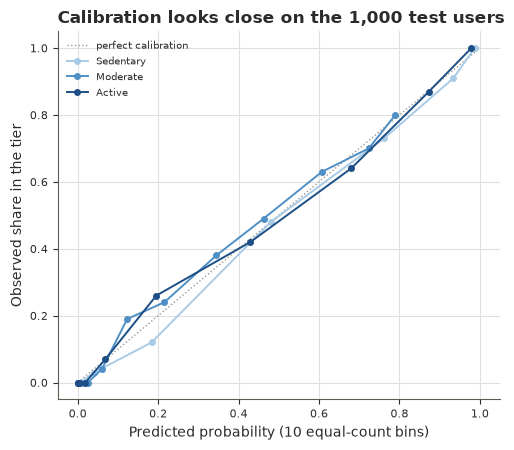

In [14]:
from sklearn.metrics import log_loss

rows, rel = [], []
for tier in TIERS:
    k = classes.index(tier)
    for split, y, p in [('training folds (out of fold)', (yc_tr == tier).to_numpy(), oof[:, k]),
                        ('test', (yc_te == tier).to_numpy(), proba_c[:, k])]:
        summary, table = calibration_summary(y, p)
        rows.append({'tier': tier, 'data': split, **summary})
        if split == 'test':
            rel.append(table.assign(tier=tier))
calib = pd.DataFrame(rows)
rel = pd.concat(rel, ignore_index=True)
display(calib.round(3))
print(f'multi-class log loss on the test set: {log_loss(yc_te, proba_c, labels=classes):.3f}')
_ = save_table(calib.round(4), '04_calibration')
_ = save_table(rel.round(4), '04_reliability')

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], color=PALETTE['baseline'], ls=':', lw=1, label='perfect calibration')
for tier in TIERS:
    part = rel[rel['tier'] == tier]
    ax.plot(part['mean_predicted'], part['observed'], 'o-', color=TIER_COLORS[tier], ms=4, lw=1.4, label=tier)
ax.set_xlabel('Predicted probability (10 equal-count bins)'); ax.set_ylabel('Observed share in the tier')
ax.set_title('Calibration looks close on the 1,000 test users')
ax.legend(fontsize=7.5, loc='upper left')
fig.tight_layout()
save_fig(fig, '04_D_calibration')
plt.show()

### Interpretation

- **Calibration looks close on this held-out sample.** For each tier, the calibration slope is 0.98–1.02 on the training
  folds and 1.01–1.11 on the test set, against an ideal of 1, and the intercepts lie between −0.20 and 0.08,
  against an ideal of 0 (Van Calster et al., 2019). In the reliability plot, the observed share in each bin stays close to the predicted
  probability.
- **Brier scores** (Brier, 1950) are 0.064 for Sedentary, 0.146 for Moderate and 0.084 for Active on the test
  set, and almost the same out of fold. The multi-class log loss is 0.458.
- **Why it matters.** The alert thresholds above treat the Sedentary probability as a real probability. That is
  now measured rather than assumed. A slope a little above 1 on the test set means the model is, if anything,
  slightly underconfident there, never overconfident.
- **What this does not show.** The slopes and Brier scores are point estimates without intervals, from one
  simulated dataset and no external validation. Calibration must be rechecked on real users, and monitored
  after release, before the probabilities drive decisions.

### Would more data help? (learning curve)

In [15]:
from sklearn.model_selection import learning_curve

sizes, tr_sc, va_sc = learning_curve(clf_models[CHOSEN], Xc_tr, yc_tr, cv=skf, scoring='accuracy',
                                     train_sizes=[50, 100, 250, 500, 1000, 2000, 3197], shuffle=True, random_state=SEED)
lc = pd.DataFrame({'train_size': sizes, 'train_accuracy': tr_sc.mean(1), 'validation_accuracy': va_sc.mean(1),
                   'validation_sd': va_sc.std(1)}).round(4)
display(lc)
_ = save_table(lc, '04_learning_curve')

,train_size,train_accuracy,validation_accuracy,validation_sd
0,50,0.8440,0.7446,0.0165
1,100,0.8140,0.7628,0.0073
2,250,0.7824,0.7723,0.0111
3,500,0.7712,0.7726,0.0134
4,1000,0.7694,0.7741,0.0113
5,2000,0.7705,0.7748,0.0098
6,3197,0.7770,0.7751,0.0094


saved outputs/tables/04_learning_curve.csv

 train_size  train_accuracy  validation_accuracy  validation_sd
         50          0.8440               0.7446         0.0165
        100          0.8140               0.7628         0.0073
        250          0.7824               0.7723         0.0111
        500          0.7712               0.7726         0.0134
       1000          0.7694               0.7741         0.0113
       2000          0.7705               0.7748         0.0098
       3197          0.7770               0.7751         0.0094


### Interpretation

- **Accuracy stops improving at about 250–500 training users.** Validation accuracy is 77.2% at 250, 77.3% at
  500 and 77.5% at 3,197. The gap between training and validation accuracy closes at the same point.
- **More users will not help; new information would.** The remaining error comes from what distance and
  calories cannot reveal about sessions, not from a shortage of examples.

## M3 Segmentation

**Features (DECISION 7).** Clustering uses standardised sessions, km per session and kcal per session: the three
independent dimensions of behaviour found in `02`. Clustering the raw totals instead would mostly rediscover
sessions, which drive all three totals.

**Choice of k (DECISION 10).** Not chosen in advance. Four measures are read together across k = 2–8:
- the Hopkins statistic, for whether there is any structure at all (Hopkins & Skellam, 1954);
- the silhouette, which is above 0.5 when segments are reasonably separated (Rousseeuw, 1987; L. Kaufman &
  Rousseeuw, 1990);
- the Davies–Bouldin index;
- bootstrap stability, measured by the adjusted Rand index (ARI; Hubert & Arabie, 1985).

In [16]:
from src.models.clustering import bootstrap_stability, hopkins, kmeans_sweep
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

Z_raw = StandardScaler().fit_transform(data[['app_sessions', 'distance_km', 'calories']])
Z = StandardScaler().fit_transform(data[['app_sessions', 'km_per_session', 'kcal_per_session']])
h_raw, h_rates = hopkins(Z_raw, m=500, seed=SEED), hopkins(Z, m=500, seed=SEED)
print(f'Hopkins statistic: totals (sessions, distance, calories) {h_raw:.3f}; '
      f'independent dimensions (sessions, km/session, kcal/session) {h_rates:.3f}')

KS = list(range(2, 9))
sweep = kmeans_sweep(Z, KS, seed=SEED)
stab = [bootstrap_stability(Z, k, B=20, seed=SEED) for k in KS]
sweep['stability_ari'] = [s[0] for s in stab]
sweep['stability_sd'] = [s[1] for s in stab]
sweep['ari_vs_tier'] = [adjusted_rand_score(data['activity_level'], KMeans(k, n_init=10, random_state=SEED).fit_predict(Z))
                        for k in KS]
display(sweep.round(3))
km3_raw = KMeans(3, n_init=10, random_state=SEED).fit_predict(Z_raw)
print('k = 3 on the totals: ARI against Activity Level =', round(adjusted_rand_score(data['activity_level'], km3_raw), 3))
_ = save_table(sweep.round(4), '04_kmeans_sweep')

Hopkins statistic: totals (sessions, distance, calories) 0.919; independent dimensions (sessions, km/session, kcal/session) 0.494


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,stability_ari,stability_sd,ari_vs_tier
0,2,11255.098,0.242,1.649,1658.001,0.285,0.440,0.003
1,3,8945.644,0.240,1.327,1687.500,0.473,0.275,0.003
2,4,7097.899,0.272,1.101,1850.805,0.626,0.285,0.190
3,5,5998.483,0.264,1.067,1870.928,0.537,0.219,0.186
4,6,5004.334,0.281,0.975,1992.013,0.570,0.241,0.166
5,7,4394.353,0.273,0.992,2005.506,0.631,0.106,0.162
6,8,3835.908,0.271,0.987,2072.649,0.893,0.042,0.145


k = 3 on the totals: ARI against Activity Level = 0.633
saved outputs/tables/04_kmeans_sweep.csv

 k    inertia  silhouette  davies_bouldin  calinski_harabasz  stability_ari  stability_sd  ari_vs_tier
 2 11255.0976      0.2421          1.6495          1658.0012         0.2852        0.4397       0.0030
 3  8945.6436      0.2400          1.3274          1687.5000         0.4732        0.2746       0.0028
 4  7097.8987      0.2723          1.1009          1850.8053         0.6260        0.2851       0.1896
 5  5998.4830      0.2642          1.0667          1870.9283         0.5368        0.2194       0.1863
 6  5004.3339      0.2812          0.9749          1992.0131         0.5702        0.2415       0.1660
 7  4394.3530      0.2729          0.9919          2005.5058         0.6307        0.1057       0.1617
 8  3835.9085      0.2705          0.9869          2072.6494         0.8926        0.0423       0.1449


### Interpretation

- **There are no natural segments.** On the three independent dimensions, the Hopkins statistic is 0.49,
  where 0.5 means evenly spread. On the raw totals it is 0.92, but that is an artefact: correlated totals leave
  most of the bounding box empty, which the statistic reads as clustering.
- **No k separates users well.** The silhouette stays between 0.24 and 0.28 for every k, far below the 0.5 that
  marks reasonable structure.
- **Stability is not validity.** Stability rises with k, from 0.29 at k = 2 to 0.89 at k = 8, because k-means
  cuts an even cloud into the same blocks every time once the blocks are small. A stable partition of
  structureless data is still arbitrary.
- **The tiers return only through sessions.** Clustered on the raw totals, k = 3 reproduces the tiers fairly
  well (ARI = 0.63), because sessions drive all three totals. On the independent dimensions, agreement with the
  tiers is at most 0.19.

,n,sessions,km_per_session,kcal_per_session
segment,,,,
3,1267,91.73,0.65,2.80
0,1281,96.99,0.85,4.18
2,1188,154.62,0.85,2.85
1,1261,156.40,0.63,4.02


,activity_level,intensity,n
0,Sedentary,higher intensity,807
1,Sedentary,lower intensity,827
2,Moderate,higher intensity,844
3,Moderate,lower intensity,889
4,Active,higher intensity,801
5,Active,lower intensity,829


saved outputs/tables/04_kmeans_profiles.csv

 segment    n  sessions  km_per_session  kcal_per_session
       3 1267     91.73            0.65              2.80
       0 1281     96.99            0.85              4.18
       2 1188    154.62            0.85              2.85
       1 1261    156.40            0.63              4.02
saved outputs/tables/04_rule_segments.csv

activity_level        intensity   n
     Sedentary higher intensity 807
     Sedentary  lower intensity 827
      Moderate higher intensity 844
      Moderate  lower intensity 889
        Active higher intensity 801
        Active  lower intensity 829


saved outputs/figures/04_C_segmentation.png


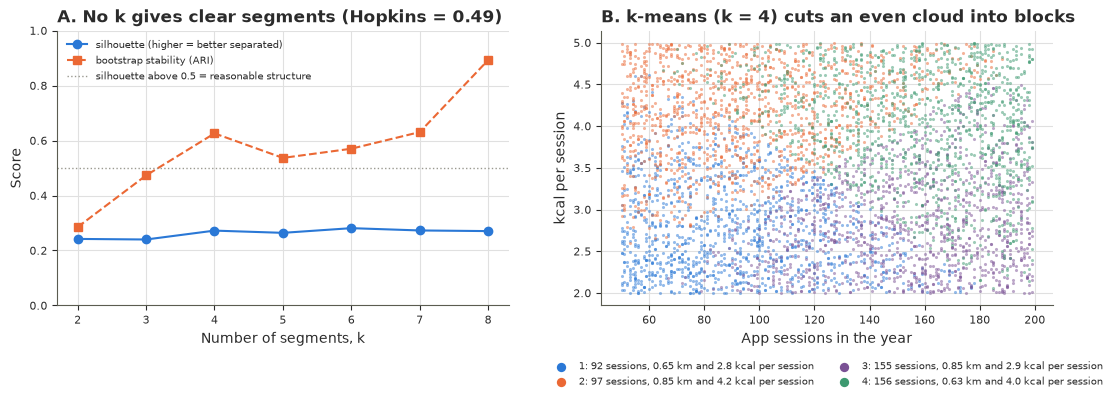

In [17]:
K = 4
km = KMeans(K, n_init=10, random_state=SEED).fit(Z)
seg = data.assign(segment=km.labels_)
prof = (seg.groupby('segment').agg(n=('user_id', 'size'), sessions=('app_sessions', 'mean'),
                                   km_per_session=('km_per_session', 'mean'), kcal_per_session=('kcal_per_session', 'mean'))
        .sort_values('sessions').round(2))
display(prof)

rule = (data.assign(intensity=np.where(data['kcal_per_session'] >= 3.5, 'higher intensity', 'lower intensity'))
        .groupby(['activity_level', 'intensity'], observed=True).size().rename('n').reset_index())
display(rule)
_ = save_table(prof.reset_index(), '04_kmeans_profiles')
_ = save_table(rule, '04_rule_segments')

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax = axes[0]
ax.plot(sweep['k'], sweep['silhouette'], 'o-', color=PALETTE['accent'], label='silhouette (higher = better separated)')
ax.plot(sweep['k'], sweep['stability_ari'], 's--', color=PALETTE['alert'], label='bootstrap stability (ARI)')
ax.axhline(0.5, color=PALETTE['baseline'], ls=':', lw=1, label='silhouette above 0.5 = reasonable structure')
ax.set_ylim(0, 1); ax.set_xlabel('Number of segments, k'); ax.set_ylabel('Score')
ax.set_title(f'A. No k gives clear segments (Hopkins = {h_rates:.2f})')
ax.legend(fontsize=7.5, loc='upper left')
ax = axes[1]
cols = [PALETTE['accent'], PALETTE['alert'], '#7a5195', '#3d9970']
order = prof.index.tolist()
order = prof.sort_values(['sessions', 'kcal_per_session']).index.tolist()
for i, sgm in enumerate(order):
    part = seg[seg['segment'] == sgm]
    r = prof.loc[sgm]
    ax.scatter(part['app_sessions'], part['kcal_per_session'], s=5, alpha=0.5, color=cols[i], lw=0,
               label=f'{i + 1}: {r.sessions:.0f} sessions, {r.km_per_session:.2f} km and {r.kcal_per_session:.1f} kcal per session')
ax.set_xlabel('App sessions in the year'); ax.set_ylabel('kcal per session')
ax.set_title('B. k-means (k = 4) cuts an even cloud into blocks')
leg = ax.legend(fontsize=7.2, markerscale=3, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=2)
for h in leg.legend_handles:
    h.set_alpha(1)
fig.tight_layout()
save_fig(fig, '04_C_segmentation')
plt.show()

### Interpretation

- **k = 4 cuts the cloud into corners**:
  1. fewer sessions, shorter and lighter sessions (92 sessions; 0.65 km and 2.8 kcal per session);
  2. fewer sessions, longer and harder sessions (97; 0.85 km and 4.2 kcal);
  3. more sessions, longer but lighter sessions (155; 0.85 km and 2.9 kcal);
  4. more sessions, shorter but harder sessions (156; 0.63 km and 4.0 kcal).
- **These are blocks, not types.** A user near a boundary is as similar to the neighbouring segment as to their
  own, so a recommendation keyed to the segment would change abruptly across an arbitrary line.
- **A rule-based alternative is just as balanced and can be explained.** Tier × intensity (above or below 3.5 kcal
  per session) gives six segments of 801–889 users each, and a user can be told exactly why they are in one.

**Decision (M3): use the rule-based segments.** k-means is not used to define user types.

## Leakage check: copies across the train/test split

What would the copy block (`01`) have done to model evaluation? The same models are scored with and without it, over 20 random splits.

In [18]:
raw = load_raw(RAW_FILE)
with_copies = clean_users(raw, drop_copy_block=False).dropna(subset=['distance_km', 'app_sessions']).reset_index(drop=True)
FIELDS = ['gender', 'age', 'activity_level', 'location', 'app_sessions', 'distance_km', 'calories']
key = lambda d: d[FIELDS].astype(str).apply('|'.join, axis=1)

memorisers = {
    '1-nearest neighbour': lambda: Pipeline([('prep', prep(NUM_C)), ('model', KNeighborsClassifier(1))]),
    'Random forest, unlimited depth': lambda: Pipeline([('prep', prep(NUM_C)), ('model', RandomForestClassifier(
        n_estimators=200, random_state=SEED, n_jobs=-1))]),
    'Logistic regression': lambda: Pipeline([('prep', prep(NUM_C)), ('model', LogisticRegression(max_iter=2000))]),
}
rows = []
for split_seed in range(20):
    for label, frame in [('copies kept', with_copies), ('copies removed', data)]:
        tr, te = train_test_split(frame, test_size=0.2, stratify=frame['activity_level'], random_state=split_seed)
        twins = int(key(te).isin(set(key(tr))).sum())
        for name, make in memorisers.items():
            m = make().fit(tr[NUM_C + CAT], tr['activity_level'].astype(str))
            rows.append({'split': split_seed, 'data': label, 'model': name, 'test_twins': twins,
                         'accuracy': accuracy_score(te['activity_level'].astype(str), m.predict(te[NUM_C + CAT]))})
leak = pd.DataFrame(rows)
summary = (leak.groupby(['model', 'data']).agg(accuracy=('accuracy', 'mean'), sd=('accuracy', 'std'),
                                              test_twins=('test_twins', 'mean')).unstack('data').round(4))
inflation = (leak.pivot_table(index=['split', 'model'], columns='data', values='accuracy')
             .assign(gain=lambda d: d['copies kept'] - d['copies removed']).groupby('model')['gain']
             .agg(['mean', 'std']).round(4))
display(summary)
display(inflation.rename(columns={'mean': 'inflation_mean', 'std': 'inflation_sd'}))
_ = save_table(leak.groupby(['model', 'data'])[['accuracy', 'test_twins']].mean().reset_index().round(4), '04_copy_leakage')
_ = save_table(inflation.reset_index().round(4), '04_copy_inflation')

accuracy                         sd                 test_twins               
data                           copies kept copies removed copies kept copies removed copies kept copies removed
model                                                                                                          
1-nearest neighbour                 0.7428         0.7175      0.0117         0.0125        87.6            0.0
Logistic regression                 0.7832         0.7800      0.0123         0.0129        87.6            0.0
Random forest, unlimited depth      0.7888         0.7682      0.0104         0.0119        87.6            0.0

,inflation_mean,inflation_sd
model,,
1-nearest neighbour,0.0253,0.0135
Logistic regression,0.0032,0.0119
"Random forest, unlimited depth",0.0207,0.0132


saved outputs/tables/04_copy_leakage.csv

                         model           data  accuracy  test_twins
           1-nearest neighbour    copies kept    0.7428        87.6
           1-nearest neighbour copies removed    0.7175         0.0
           Logistic regression    copies kept    0.7832        87.6
           Logistic regression copies removed    0.7800         0.0
Random forest, unlimited depth    copies kept    0.7888        87.6
Random forest, unlimited depth copies removed    0.7682         0.0
saved outputs/tables/04_copy_inflation.csv

                         model   mean    std
           1-nearest neighbour 0.0253 0.0135
           Logistic regression 0.0032 0.0119
Random forest, unlimited depth 0.0207 0.0132


### Interpretation

- **Copies leak across the split.** Over 20 random 80/20 splits with the copy block kept, each test set holds
  about 88 records that have an exact twin in the training set.
- **Memorising models are flattered, and only they are.**
  - 1-nearest neighbour gains 2.5 points of accuracy (SD 1.4).
  - A random forest with unlimited depth gains 2.1 points (SD 1.3).
  - Logistic regression, which cannot memorise single records, gains 0.3 points (SD 1.2), which is noise.
- **Why it matters for engineering.** Duplicates distort the model *comparison*, not just the counts.
  With the copies kept, the random forest (78.9%) would edge past logistic regression (78.3%) and could be
  chosen for the wrong reason. Deduplication has to happen before any split, and a check that no test record
  has a twin in training belongs in the pipeline's tests (Kapoor & Narayanan, 2023).

## Sensitivity analysis

The main results, re-run under each alternative cleaning decision from `01`.

In [19]:
def run_variant(frame):
    """Repeat the main split and the chosen models on one cleaning variant."""
    f = frame.dropna(subset=['distance_km', 'app_sessions']).reset_index(drop=True)
    tr, te = train_test_split(f, test_size=0.2, stratify=f['activity_level'], random_state=SEED)
    reg = clone(reg_models['Linear: sessions only']).fit(tr[NUM_R + CAT], tr['calories'])
    clf = clone(clf_models[CHOSEN]).fit(tr[NUM_C + CAT], tr['activity_level'].astype(str))
    return {'users': len(f),
            'pearson_sessions_distance': f[['app_sessions', 'distance_km']].corr().iat[0, 1],
            'calories_test_r2': r2_score(te['calories'], reg.predict(te[NUM_R + CAT])),
            'tier_test_accuracy': accuracy_score(te['activity_level'].astype(str), clf.predict(te[NUM_C + CAT]))}

variants = {
    'As decided (copies removed, two distances blanked)': clean_users(raw),
    'Two distances kept as recorded (920 and 10 km)': clean_users(raw, suspect_distances='keep'),
    'Two distances corrected (92 and 100 km)': clean_users(raw, suspect_distances='correct'),
    'Copy block kept': clean_users(raw, drop_copy_block=False),
}
sens = pd.DataFrame([{'variant': k, **run_variant(v)} for k, v in variants.items()]).round(4)
display(sens)
_ = save_table(sens, '04_sensitivity')

,variant,users,pearson_sessions_distance,calories_test_r2,tier_test_accuracy
0,"As decided (copies removed, two distances blan...",4997,0.8572,0.6373,0.7860
1,Two distances kept as recorded (920 and 10 km),4999,0.8221,0.6378,0.7800
2,Two distances corrected (92 and 100 km),4999,0.8570,0.6378,0.7810
3,Copy block kept,5295,0.8591,0.6327,0.7913


saved outputs/tables/04_sensitivity.csv

                                           variant  users  pearson_sessions_distance  calories_test_r2  tier_test_accuracy
As decided (copies removed, two distances blanked)   4997                     0.8572            0.6373              0.7860
    Two distances kept as recorded (920 and 10 km)   4999                     0.8221            0.6378              0.7800
           Two distances corrected (92 and 100 km)   4999                     0.8570            0.6378              0.7810
                                   Copy block kept   5295                     0.8591            0.6327              0.7913


### Interpretation

- **No conclusion depends on a cleaning judgement.** Across the four variants, the calorie model's test R² stays
  between 0.633 and 0.638 and the tier classifier's accuracy between 78.0% and 79.1%.
- **Only one statistic moves.** Keeping the two ×10 distances lowers the sessions–distance correlation from
  0.857 to 0.822: one bad value among 5,000 is enough to weaken a headline correlation.
- **The copy block's effect on these scores is small** (79.1% against 78.6% on this split, and +0.3 points on
  average over the 20 splits above), because the chosen models do not memorise. Its effect on flexible models
  is shown above.

## Inference contract: what the shipped models accept

What happens when an imported record is not like the training data?

In [20]:
from src.data.fitness import check_tier_inputs

# 1. The contract on the numbers the shipped tier model reads (distance and calories).
viol = check_tier_inputs(data['distance_km'], data['calories'])
print('cleaned users with distance and calories that break the contract:', int((viol != '').sum()), 'of', len(data))
as_recorded = clean_users(raw, suspect_distances='keep')
v = check_tier_inputs(as_recorded['distance_km'], as_recorded['calories'])
display(as_recorded.loc[v != '', ['user_id', 'distance_km', 'calories']].assign(violation=v[v != '']))

# 2. A model with categorical inputs has a second failure mode: a category it never saw in training.
probe = Xc_te.head(1).assign(location='Remote')
try:
    fitted_clf['Logistic regression: all inputs'].predict(probe)
except ValueError as e:
    print('model with demographics, unseen location "Remote":', type(e).__name__, '-', str(e).split('.')[0])
print('shipped model, same record:', fitted_clf[CHOSEN].predict(probe)[0], '(it never reads location)')

cleaned users with distance and calories that break the contract: 0 of 4997


,user_id,distance_km,calories,violation
1998,1999,920.0,909,no session count fits both values
2066,2067,10.0,245,no session count fits both values
4906,4907,NaN,582,missing value


model with demographics, unseen location "Remote": ValueError - Found unknown categories ['Remote'] in column 1 during transform
shipped model, same record: Moderate (it never reads location)


### Interpretation

- **The shipped tier model needs a contract on its two inputs.** A distance and a calorie count are accepted
  only if some whole number of sessions between 50 and 199 could have produced both, at 0.5–1.0 km and 2–5 kcal
  per session (`src/data/fitness.py`, `check_tier_inputs`).
- **The contract catches what the column screens missed.** All 4,997 cleaned users pass. Run on the data as
  recorded, it rejects exactly the two ×10 distances found in `01` (920 km and 10 km) and the missing one, without
  needing sessions.
- **Categorical inputs add a failure mode.** The model with demographics raises an error on a location it never
  saw ("Remote"). The shipped model never reads location, so it cannot fail this way: one more reason to drop
  fields that add nothing.
- **Engineering decision.** A record that fails the contract gets no prediction. The app falls back to asking the
  user or to the default starting plan, and the failure is logged.

In [21]:
out = test[['user_id', 'gender', 'location', 'age_band', 'activity_level', 'app_sessions', 'calories']].copy()
out['calories_pred'] = fitted_reg['Linear: sessions only'].predict(Xr_te)
out['tier_pred'] = test_pred[CHOSEN]
out['p_sedentary'] = p_sed
_ = save_interim(out, '04_test_predictions.csv')

wrote data/interim/04_test_predictions.csv  (1000 rows)


## Implications for software engineering decisions

| # | Finding | Evidence | Decision for the team |
|---|---|---|---|
| 1 | Activity Level is a rule on sessions | A two-split tree recovers 99.5 / 149.5; 100% accuracy | Implement the tier as a documented, unit-tested function; no machine learning (Zinkevich, 2017) |
| 2 | Calorie prediction is at the structural benchmark | Test R² 0.637 (95% CI 0.607–0.665), consistent with the theoretical 0.630; linear ≥ random forest ≥ gradient boosting | Ship the one-parameter linear model. To improve estimates, collect better signals (session duration, heart rate, with consent), not a bigger model |
| 3 | Error grows with activity | Breusch–Pagan p < 0.001; a constant interval covers 58% of Active users | Show calories as a range that widens with activity, never a single number |
| 4 | Tier from imported activity: 79%, at the structural benchmark | Logistic regression on distance and calories, chosen on training folds: 78.6% vs Bayes rule 78.0%; no Sedentary ↔ Active confusion; calibration close on the test set | Use it only to choose a starting plan, and let the user change it |
| 5 | Alerts trade precision for recall | Thresholds set on training folds: 0.50 / 0.25 / 0.11 → test recall 0.90 / 0.96 / 0.99 | Make the threshold a configuration value owned by the product team, set from agreed error costs on validation data; log outcomes and review it |
| 6 | Demographics add nothing | Tier: 77.5% without them vs 77.4% with them (cross-validated); demographics alone 33.7% (AUC 0.51); calories: permutation importance ≈ 0 | Do not collect or use gender, age or location to personalise (data minimisation, `05`) |
| 7 | No natural segments | Hopkins 0.49; silhouette ≤ 0.28 at every k | Use transparent rule-based segments; never present clusters as user types |
| 8 | Copies flatter flexible models | +2.5 points (1-NN), +2.1 (random forest); logistic +0.3 | Deduplicate at ingestion with idempotent event IDs; split by user after deduplication; test for twins across splits |
| 9 | One-column checks miss relational errors | IQR misses the 10 km error; the per-session rule catches both | Validate records against cross-field rules at ingestion (data contracts; Polyzotis et al., 2019) and quarantine failures |
| 10 | Accuracy plateaus at about 500 users | Learning curve flat from 500 to 3,197 | Prioritise new signals over more rows of the same signals |
| 11 | The file has no app-performance data | No crash, latency or sync logs; 5.6% of rows were copies | Add performance telemetry, and treat the copy block as a pipeline defect to fix |
| 12 | Flexible models memorise | Training-fold gap: gradient boosting 11.8 points, random forest 6.4, logistic 0.2 | Report training, validation and test scores side by side in every model review |
| 13 | Imported records can be impossible | The input contract rejects both ×10 distances; a model with categories fails on an unseen location | Validate every imported record against the contract; no prediction on failure; models take only the fields they need |

Before the recommendation feature is rolled out to everyone, it should be tested against the current app in a
randomised experiment with guardrail metrics (Kohavi et al., 2020). The invariants found here (2–5 kcal and
0.5–1.0 km per session) make good drift monitors: if they change, the app or the data pipeline has changed
(Sculley et al., 2015).

## References

Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review,
78*(1), 1–3. https://doi.org/10.1175/1520-0493(1950)078<0001:VOFEIT>2.0.CO;2

Breusch, T. S., & Pagan, A. R. (1979). A simple test for heteroscedasticity and random coefficient variation.
*Econometrica, 47*(5), 1287–1294. https://doi.org/10.2307/1911963

Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in
performance evaluation. *Journal of Machine Learning Research, 11*, 2079–2107.

Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning
algorithms. *Neural Computation, 10*(7), 1895–1923. https://doi.org/10.1162/089976698300017197

Hopkins, B., & Skellam, J. G. (1954). A new method for determining the type of distribution of plant
individuals. *Annals of Botany, 18*(2), 213–227. https://doi.org/10.1093/oxfordjournals.aob.a083391

Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218.
https://doi.org/10.1007/BF01908075

James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An introduction to statistical learning: With
applications in R* (2nd ed.). Springer. https://doi.org/10.1007/978-1-0716-1418-1

Kapoor, S., & Narayanan, A. (2023). Leakage and the reproducibility crisis in machine-learning-based science.
*Patterns, 4*(9), Article 100804. https://doi.org/10.1016/j.patter.2023.100804

Kaufman, L., & Rousseeuw, P. J. (1990). *Finding groups in data: An introduction to cluster analysis*. Wiley.

Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and
avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), Article 15.
https://doi.org/10.1145/2382577.2382579

Koenker, R., & Bassett, G. (1978). Regression quantiles. *Econometrica, 46*(1), 33–50.
https://doi.org/10.2307/1913643

Kohavi, R., Tang, D., & Xu, Y. (2020). *Trustworthy online controlled experiments: A practical guide to A/B
testing*. Cambridge University Press. https://doi.org/10.1017/9781108653985

Polyzotis, N., Zinkevich, M., Roy, S., Breck, E., & Whang, S. (2019). Data validation for machine learning.
*Proceedings of Machine Learning and Systems, 1*, 334–347.

Provost, F., & Fawcett, T. (2013). *Data science for business: What you need to know about data mining and
data-analytic thinking*. O'Reilly Media.

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis.
*Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

Sculley, D., Holt, G., Golovin, D., Davydov, E., Phillips, T., Ebner, D., Chaudhary, V., Young, M., Crespo, J.-F.,
& Dennison, D. (2015). Hidden technical debt in machine learning systems. *Advances in Neural Information
Processing Systems, 28*, 2503–2511.

Van Calster, B., McLernon, D. J., van Smeden, M., Wynants, L., & Steyerberg, E. W. (2019). Calibration: The
Achilles heel of predictive analytics. *BMC Medicine, 17*, Article 230. https://doi.org/10.1186/s12916-019-1466-7

Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the
American Statistical Association, 22*(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953

Zinkevich, M. (2017). *Rules of machine learning: Best practices for ML engineering*. Google.
https://developers.google.com/machine-learning/guides/rules-of-ml